# Super-Resolution Benchmark Results Analysis Notebook

This notebook analyzes and visualizes benchmark experiment results produced by the super-resolution pipeline. **It only reads saved result files and never trains any models.**

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

summary_csv = Path("../results/summary.csv")
if not summary_csv.exists():
    summary_csv = Path("results/summary.csv")

if not summary_csv.exists():
    print("Results summary CSV not found at results/summary.csv!")
    print("Please run `python scripts/aggregate_results.py` after running experiments.")
else:
    df = pd.read_csv(summary_csv)
    print(f"Successfully loaded summary with {len(df)} rows.")
    display(df.head())

Successfully loaded summary with 97 rows.


,experiment,model,dataset,scale,degradation,noise_sigma,n_images,param_count,mean_inference_time_s,mean_psnr,mean_ssim
0,baselines_x2_clean,nearest,Set5,2,bicubic_down_x2,0.0,5,0,0.000930,30.858403,0.900162
1,baselines_x2_clean,nearest,Set14,2,bicubic_down_x2,0.0,14,0,0.000384,28.581975,0.846429
2,baselines_x2_clean,nearest,BSD100,2,bicubic_down_x2,0.0,100,0,0.000215,28.423555,0.825264
3,baselines_x2_clean,nearest,Urban100,2,bicubic_down_x2,0.0,100,0,0.000911,25.627591,0.821119
4,baselines_x2_clean,bilinear,Set5,2,bicubic_down_x2,0.0,5,0,0.000673,32.254800,0.911932


In [2]:
# Configurable variables for pivot table
TARGET_SCALE = 4
TARGET_NOISE_SIGMA = 0.0

if 'df' in locals() and not df.empty:
    filtered_df = df[(df["scale"] == TARGET_SCALE) & (df["noise_sigma"] == TARGET_NOISE_SIGMA)]
    if filtered_df.empty:
        print(f"No entries found for scale={TARGET_SCALE} and noise_sigma={TARGET_NOISE_SIGMA}")
    else:
        pivot_psnr = filtered_df.pivot(index="model", columns="dataset", values="mean_psnr")
        pivot_ssim = filtered_df.pivot(index="model", columns="dataset", values="mean_ssim")
        print(f"=== Mean PSNR (dB) for Scale x{TARGET_SCALE}, Noise Sigma {TARGET_NOISE_SIGMA} ===")
        display(pivot_psnr)
        print(f"=== Mean SSIM for Scale x{TARGET_SCALE}, Noise Sigma {TARGET_NOISE_SIGMA} ===")
        display(pivot_ssim)

ValueError: Index contains duplicate entries, cannot reshape

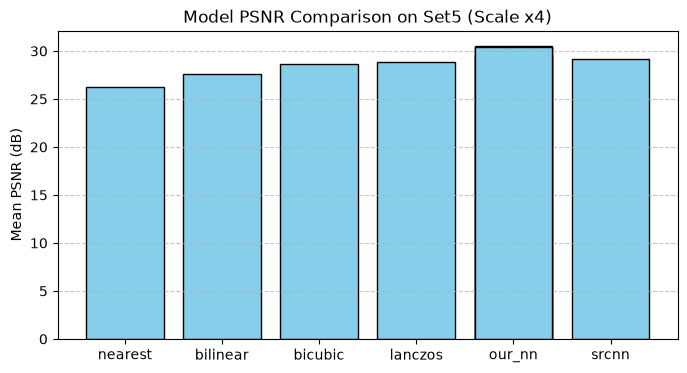

In [3]:
# Bar chart of PSNR per model for a chosen dataset
CHOSEN_DATASET = "Set5"

if 'df' in locals() and not df.empty:
    ds_sub = df[(df["dataset"] == CHOSEN_DATASET) & (df["scale"] == TARGET_SCALE) & (df["noise_sigma"] == TARGET_NOISE_SIGMA)]
    if not ds_sub.empty and "mean_psnr" in ds_sub.columns:
        plt.figure(figsize=(8, 4))
        plt.bar(ds_sub["model"], ds_sub["mean_psnr"], color="skyblue", edgecolor="black")
        plt.ylabel("Mean PSNR (dB)")
        plt.title(f"Model PSNR Comparison on {CHOSEN_DATASET} (Scale x{TARGET_SCALE})")
        plt.grid(axis="y", linestyle="--", alpha=0.7)
        plt.show()
    else:
        print(f"No data available for dataset '{CHOSEN_DATASET}'.")

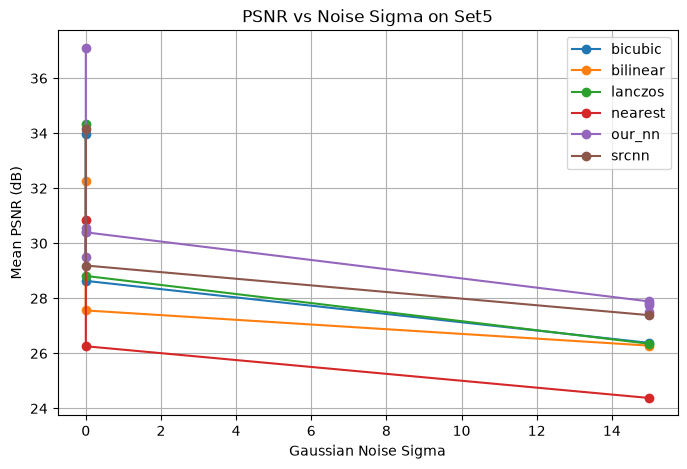

In [4]:
# Line plot of PSNR vs noise_sigma per model
if 'df' in locals() and not df.empty:
    plt.figure(figsize=(8, 5))
    for model_name, grp in df[df["dataset"] == CHOSEN_DATASET].groupby("model"):
        grp_sorted = grp.sort_values("noise_sigma")
        plt.plot(grp_sorted["noise_sigma"], grp_sorted["mean_psnr"], marker="o", label=model_name)
    plt.xlabel("Gaussian Noise Sigma")
    plt.ylabel("Mean PSNR (dB)")
    plt.title(f"PSNR vs Noise Sigma on {CHOSEN_DATASET}")
    plt.legend()
    plt.grid(True)
    plt.show()

In [5]:
def show_sample_comparison(experiment_name: str, dataset_name: str, image_stem: str, models: list):
    """Displays LR / each model's SR / HR side by side from results/<exp>/samples/."""
    base_results = Path("../results") if Path("../results").exists() else Path("results")
    samples_dir = base_results / experiment_name / "samples" / dataset_name
    
    if not samples_dir.exists():
        print(f"Samples directory '{samples_dir}' does not exist.")
        return
    
    imgs = []
    titles = []
    
    lr_path = samples_dir / f"{image_stem}_lr.png"
    if lr_path.exists():
        imgs.append(Image.open(lr_path))
        titles.append("LR (Nearest Up)")
        
    for m in models:
        sr_path = samples_dir / f"{image_stem}_{m}_sr.png"
        if sr_path.exists():
            imgs.append(Image.open(sr_path))
            titles.append(f"SR ({m})")
            
    hr_path = samples_dir / f"{image_stem}_hr.png"
    if hr_path.exists():
        imgs.append(Image.open(hr_path))
        titles.append("HR (GT)")
        
    if not imgs:
        print("No sample images found.")
        return
        
    fig, axes = plt.subplots(1, len(imgs), figsize=(4 * len(imgs), 4))
    if len(imgs) == 1:
        axes = [axes]
    for ax, img, title in zip(axes, imgs, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Example invocation (adjust params when samples exist)
# show_sample_comparison('smoke_test', 'test_dummy', 'img_001', ['srcnn'])

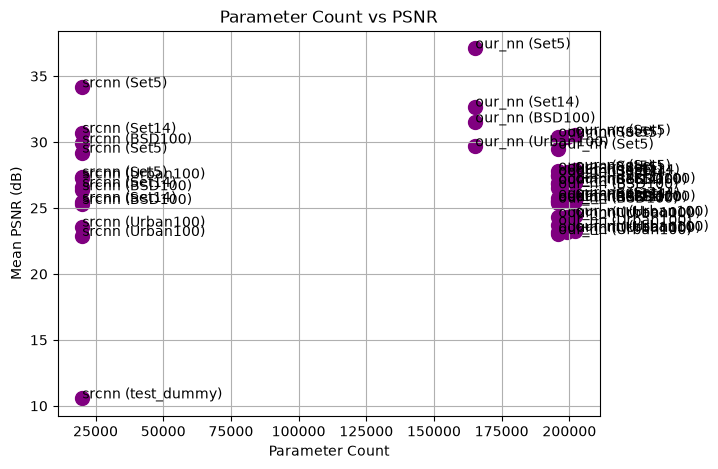

In [6]:
# Parameter count vs PSNR scatter plot
if 'df' in locals() and not df.empty:
    nn_df = df[df["param_count"] > 0]
    if not nn_df.empty:
        plt.figure(figsize=(7, 5))
        plt.scatter(nn_df["param_count"], nn_df["mean_psnr"], color="purple", s=100)
        for _, r in nn_df.iterrows():
            plt.annotate(f"{r['model']} ({r['dataset']})", (r["param_count"], r["mean_psnr"]))
        plt.xlabel("Parameter Count")
        plt.ylabel("Mean PSNR (dB)")
        plt.title("Parameter Count vs PSNR")
        plt.grid(True)
        plt.show()

In [8]:
def analyze_psnr_gap(experiment_name: str, model1: str, model2: str):
    """Reads metrics.csv of an experiment and displays per-image scores sorted by PSNR gap."""
    base_results = Path("../results") if Path("../results").exists() else Path("results")
    m_csv = base_results / experiment_name / "metrics.csv"
    if not m_csv.exists():
        print(f"metrics.csv not found for experiment '{experiment_name}'.")
        return
    
    m_df = pd.read_csv(m_csv)
    m1_df = m_df[m_df["model"] == model1][["dataset", "image", "psnr"]].rename(columns={"psnr": f"psnr_{model1}"})
    m2_df = m_df[m_df["model"] == model2][["dataset", "image", "psnr"]].rename(columns={"psnr": f"psnr_{model2}"})
    
    merged = pd.merge(m1_df, m2_df, on=["dataset", "image"])
    merged["psnr_gap"] = (merged[f"psnr_{model1}"] - merged[f"psnr_{model2}"]).abs()
    merged.sort_values(by="psnr_gap", ascending=False, inplace=True)
    
    print(f"=== Per-Image PSNR Gap between {model1} and {model2} ({experiment_name}) ===")
    display(merged)

# Example invocation
# analyze_psnr_gap('baselines_x4_clean', 'bicubic', 'nearest')